## 4.2. 分支结构

### 4.2.1. 静态分支（Static Branch）

 **在图编译阶段就完全确定节点的下游候选节点**

特点：

- 下游节点集合固定，数量、目标在编译时确定
- 运行时可选择**一个或多个**下游目标
- 可以用来做条件分支，但不生成新的节点

#### 4.2.1.1. 并行节点

最简单的静态分支形式。

在同一无条件分支的节点在同一个**超步**被激活。

{
    'topic': '猫咪',
    'poem': '《猫》\n\n雪爪轻翻月下窗，  \n狸奴卧听竹风凉。  \n忽追灯影穿帘去，  \n惊落梅花满地香。',
    'joke': '猫咪为什么总能准时下班？\n\n因为它一到点就“喵”准了！'
}

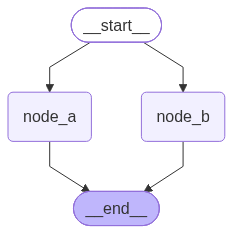

In [3]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import MessagesState
from langchain.messages import HumanMessage
import os
from rich import print as rprint
from dotenv import load_dotenv
from langchain_openai import ChatOpenAI

# 从.env文件中加载环境变量
load_dotenv(override=True, verbose=True,dotenv_path="/Users/skk/Developer/lang-chain-learn/conf/.env")

OPENAI_API_KEY = os.environ["OPENAI_API_KEY"]
OPENAI_API_BASE = os.environ["OPENAI_API_BASE"]  # 与本项目 .env 中的名称一致

model = ChatOpenAI(
    model="gpt-6-luna",  # 当前配置已验证可用；原 gpt-5.5 返回模型权限 403
    api_key=OPENAI_API_KEY,
    base_url=OPENAI_API_BASE,
)

class OverAllState(TypedDict):
    topic: str
    poem: str
    joke: str

def node_a(state: OverAllState) -> OverAllState:
    poem = model.invoke(
        [
            HumanMessage(f"写一首关于 {state['topic']} 的七言绝句")
        ]
    ).content
    return {
        "poem": poem
    }

def node_b(state: OverAllState) -> OverAllState:
    joke = model.invoke(
        [
            HumanMessage(f"写一个关于 {state['topic']} 的笑话")
        ]
    ).content
    return {
        "joke": joke
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_edge(START, "node_a")
builder.add_edge(START, "node_b")

builder.add_edge("node_a", END)
builder.add_edge("node_b", END)

graph = builder.compile()
res = graph.invoke({"topic": "猫咪"})
rprint(res)

from IPython.display import display

display(graph)

突然发现 model.invoke 的返回值 和 graph.invoke 的返回值是不同的。具体在总结部分。




#### 4.2.1.2 条件分支
**`StateGraph`** 提供了 **`add_conditional_edges`** 方法，用于从某个上游节点出发，根据运行时状态选择下游节点。
方法签名:
```python
def add_conditional_edges(
    self,
    source: str,
    path: Callable[..., Hashable | Sequence[Hashable]]
    | Callable[..., Awaitable[Hashable | Sequence[Hashable]]]
    | Runnable[Any, Hashable | Sequence[Hashable]],
    path_map: dict[Hashable, str] | list[str] | None = None,
) -> Self:
```

- **`source`**：条件分支的起始节点；
- **`path`**：路由规则，是一个可执行对象，通常是函数
- **`path_map`**：路由规则的返回值到真实节点名之间的映射关系。

**`path`** 返回值表示跳转的目标节点。在 `path_map` 中找不到的情况下，`path` 必须返回合法的节点名。如果返回`END`, 则表示执行结束。

即可以是：

- 字符串或特殊对象 **`END`** 表示的单个目标；
- 字符串或特殊对象 **`END`** 表示的多个目标组成的序列；


**`path_map`** 

- 可以省略，即取默认值 **`None`**，此时 **`path`** 返回值中出现的字符串必须是合法的节点名称。

- 可以是字典，维护 **`path`** 返回值和真实节点的映射。

- 也可以是列表，如下

  ```python
  path_map=["node_a", "node_b", "node_c"]
  ```

  相当于

  ```python
  path_map={
      "node_a": "node_a",
      "node_b": "node_b",
      "node_c": "node_c",
  }
  ```

1. 不使用 `path_map`

{
    'topic': '猫咪',
    'poem': '月下狸奴卧绣床，  \n尾扫微尘带月光。  \n偷看游鱼穿竹影，  \n一声软唤入斜阳。',
    'content_type': '诗'
}

{
    'topic': '猫咪',
    'joke': '猫咪为什么总爱坐在电脑旁边？\n\n因为它想当一名“程序猿”……不对，是“程序喵”！',
    'content_type': '笑话'
}

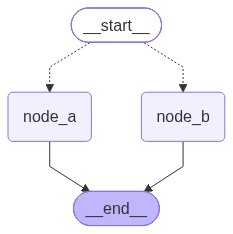

In [4]:
from typing import TypedDict, Literal
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import MessagesState
from langchain.messages import HumanMessage
import os
from rich import print as rprint
from dotenv import load_dotenv
from langchain_openai import ChatOpenAI

# 从.env文件中加载环境变量
load_dotenv(override=True, verbose=True,dotenv_path="/Users/skk/Developer/lang-chain-learn/conf/.env")

OPENAI_API_KEY = os.environ["OPENAI_API_KEY"]
OPENAI_API_BASE = os.environ["OPENAI_API_BASE"]  # 与本项目 .env 中的名称一致

model = ChatOpenAI(
    model="gpt-6-sol",  # 当前配置已验证可用；原 gpt-5.5 返回模型权限 403
    api_key=OPENAI_API_KEY,
    base_url=OPENAI_API_BASE,
)

class OverAllState(TypedDict):
    topic: str
    poem: str
    joke: str
    content_type: str

def router(state: OverAllState) -> Literal["node_a", "node_b"]:
    if "诗" in state["content_type"]:
        return "node_a"
    return "node_b"


def node_a(state: OverAllState) -> OverAllState:
    poem = model.invoke(
        [
            HumanMessage(f"写一首关于 {state['topic']} 的七言绝句")
        ]
    ).content
    return {
        "poem": poem
    }

def node_b(state: OverAllState) -> OverAllState:
    joke = model.invoke(
        [
            HumanMessage(f"写一个关于 {state['topic']} 的笑话")
        ]
    ).content
    return {
        "joke": joke
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
# 如果不注释下面两行，无论如何都进入 node_a”和“无论如何都进入 node_b”。这两条边是固定存在的，不会因为后面又加了 add_conditional_edges 而被覆盖或替代。
# builder.add_edge(START, "node_a")
# builder.add_edge(START, "node_b")
builder.add_conditional_edges(START,router)
# builder.add_edge("node_a", END)
# builder.add_edge("node_b", END)

graph = builder.compile()
res = graph.invoke({"topic": "猫咪",'content_type':"诗"})
rprint(res)
print("====="*10)
res = graph.invoke({"topic": "猫咪",'content_type':"笑话"})
print("====="*10)
rprint(res)
from IPython.display import display

display(graph)

观察图结构可以发现，**`__start__`**指向**`node_a`**和**`node_b`**的线是虚线，这表示节点的跳转是有条件的，不是固定的。

#### 4.2.1.2.1 使用 `path_map`
如果不希望路由函数直接返回节点名，而是返回业务语义更强的标识，可以使用 **`path_map`** 进行映射。如下：

* key: 别名
* value: 真实节点名

{
    'topic': '猫咪',
    'poem': '**《猫咪》**\n\n绒身懒卧小窗边，  \n月落轻敲竹影眠。  \n忽见花间飞蝶起，  \n翻身扑去尾翩翩。',
    'content_type': '诗'
}

{
    'topic': '猫咪',
    'joke': '猫咪为什么喜欢坐在电脑旁边？\n\n因为它想当“程序猿”的主管，随时检查你有没有摸鱼。',
    'content_type': '笑话'
}

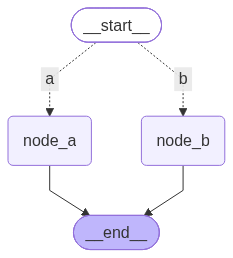

In [6]:
from typing import TypedDict, Literal
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import MessagesState
from langchain.messages import HumanMessage
import os
from rich import print as rprint
from dotenv import load_dotenv
from langchain_openai import ChatOpenAI

# 从.env文件中加载环境变量
load_dotenv(override=True, verbose=True,dotenv_path="/Users/skk/Developer/lang-chain-learn/conf/.env")

OPENAI_API_KEY = os.environ["OPENAI_API_KEY"]
OPENAI_API_BASE = os.environ["OPENAI_API_BASE"]  # 与本项目 .env 中的名称一致

model = ChatOpenAI(
    model="gpt-6-sol",  # 当前配置已验证可用；原 gpt-5.5 返回模型权限 403
    api_key=OPENAI_API_KEY,
    base_url=OPENAI_API_BASE,
)

class OverAllState(TypedDict):
    topic: str
    poem: str
    joke: str
    content_type: str

def router(state: OverAllState) -> Literal["node_a", "node_b"]:
    if "诗" in state["content_type"]:
        return "a"
    return "b"


def node_a(state: OverAllState) -> OverAllState:
    poem = model.invoke(
        [
            HumanMessage(f"写一首关于 {state['topic']} 的七言绝句")
        ]
    ).content
    return {
        "poem": poem
    }

def node_b(state: OverAllState) -> OverAllState:
    joke = model.invoke(
        [
            HumanMessage(f"写一个关于 {state['topic']} 的笑话")
        ]
    ).content
    return {
        "joke": joke
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_conditional_edges(START,router,{
    "a": "node_a",
    "b": "node_b",
})


graph = builder.compile()
res = graph.invoke({"topic": "猫咪",'content_type':"诗"})
rprint(res)
print("====="*10)
res = graph.invoke({"topic": "猫咪",'content_type':"笑话"})
print("====="*10)
rprint(res)
from IPython.display import display

display(graph)

#### 4.2.1.3 同时路由至多个节点

**`add_conditional_edges`** 也支持一次路由到多个下游节点（也就是不同分支去不同的节点序列）。

1. 不使用 `path_map`

{
    'topic': '猫咪',
    'poem': '**《猫咪》**\n\n月下狸奴卧竹帘，  \n风摇小爪戏花尖。  \n偷来鱼影惊春水，  \n懒向人前理玉髯。',
    'content_type': '诗'
}

{
    'topic': '猫咪',
    'joke': '猫咪为什么总爱坐在电脑旁边？\n\n因为它想当“程序猿”……不对，是“程序喵”！',
    'content_type': '笑话'
}

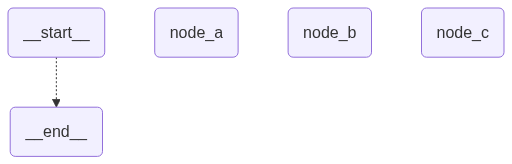

In [2]:
from typing import TypedDict, Literal
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import MessagesState
from langchain.messages import HumanMessage
import os
from rich import print as rprint
from dotenv import load_dotenv
from langchain_openai import ChatOpenAI
from collections.abc import Sequence
# 从.env文件中加载环境变量
load_dotenv(override=True, verbose=True,dotenv_path="/Users/skk/Developer/lang-chain-learn/conf/.env")

OPENAI_API_KEY = os.environ["OPENAI_API_KEY"]
OPENAI_API_BASE = os.environ["OPENAI_API_BASE"]  # 与本项目 .env 中的名称一致

model = ChatOpenAI(
    model="gpt-6-sol",  # 当前配置已验证可用；原 gpt-5.5 返回模型权限 403
    api_key=OPENAI_API_KEY,
    base_url=OPENAI_API_BASE,
)

class OverAllState(TypedDict):
    topic: str
    poem: str
    joke: str
    ci_poem: str
    content_type: str

def router(state: OverAllState) -> Sequence[Literal["node_a", "node_b", "node_c"]]:
    if "诗" in state["content_type"]:
        return ["node_a","node_c"]
    return ["node_b","node_c"]


def node_a(state: OverAllState) -> OverAllState:
    poem = model.invoke(
        [
            HumanMessage(f"写一首关于 {state['topic']} 的七言绝句")
        ]
    ).content
    return {
        "poem": poem
    }

def node_b(state: OverAllState) -> OverAllState:
    joke = model.invoke(
        [
            HumanMessage(f"写一个关于 {state['topic']} 的笑话")
        ]
    ).content
    return {
        "joke": joke
    }

def node_c(state: OverAllState) -> OverAllState:
    ci_poem = model.invoke([HumanMessage(f"写一首关于 {state['topic']} 的词")]).content

    return {
        "ci_poem": ci_poem
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_node("node_c", node_c)
builder.add_conditional_edges(START,router)


graph = builder.compile()
res = graph.invoke({"topic": "猫咪",'content_type':"诗"})
rprint(res)
print("====="*10)
res = graph.invoke({"topic": "猫咪",'content_type':"笑话"})
print("====="*10)
rprint(res)
from IPython.display import display

display(graph)

{
    'topic': '猫咪',
    'poem': '《猫咪》\n\n窗前懒卧晒冬阳，  \n细步轻移过粉墙。  \n忽见花间飞彩蝶，  \n回眸一跃捉春光。',
    'content_type': '诗'
}

{'topic': '猫咪', 'joke': '猫咪为什么总爱盯着电脑？\n\n因为它想抓住“鼠标”。', 'content_type': '笑话'}

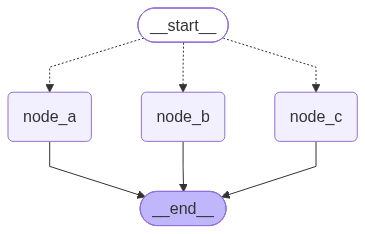

In [3]:
from typing import TypedDict, Literal
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import MessagesState
from langchain.messages import HumanMessage
import os
from rich import print as rprint
from dotenv import load_dotenv
from langchain_openai import ChatOpenAI
from collections.abc import Sequence
# 从.env文件中加载环境变量
load_dotenv(override=True, verbose=True,dotenv_path="/Users/skk/Developer/lang-chain-learn/conf/.env")

OPENAI_API_KEY = os.environ["OPENAI_API_KEY"]
OPENAI_API_BASE = os.environ["OPENAI_API_BASE"]  # 与本项目 .env 中的名称一致

model = ChatOpenAI(
    model="gpt-6-sol",  # 当前配置已验证可用；原 gpt-5.5 返回模型权限 403
    api_key=OPENAI_API_KEY,
    base_url=OPENAI_API_BASE,
)

class OverAllState(TypedDict):
    topic: str
    poem: str
    joke: str
    ci_poem: str
    content_type: str

def router(state: OverAllState) -> Sequence[Literal["node_a", "node_b", "node_c"]]:
    if "诗" in state["content_type"]:
        return ["node_a","node_c"]
    return ["node_b","node_c"]


def node_a(state: OverAllState) -> OverAllState:
    poem = model.invoke(
        [
            HumanMessage(f"写一首关于 {state['topic']} 的七言绝句")
        ]
    ).content
    return {
        "poem": poem
    }

def node_b(state: OverAllState) -> OverAllState:
    joke = model.invoke(
        [
            HumanMessage(f"写一个关于 {state['topic']} 的笑话")
        ]
    ).content
    return {
        "joke": joke
    }

def node_c(state: OverAllState) -> OverAllState:
    ci_poem = model.invoke([HumanMessage(f"写一首关于 {state['topic']} 的词")]).content

    return {
        "ci_poem": ci_poem
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_node("node_c", node_c)
builder.add_conditional_edges(START,router,path_map={
        "node_a": "node_a",
        "node_b": "node_b",
        "node_c": "node_c",
    })


graph = builder.compile()
res = graph.invoke({"topic": "猫咪",'content_type':"诗"})
rprint(res)
print("====="*10)
res = graph.invoke({"topic": "猫咪",'content_type':"笑话"})
print("====="*10)
rprint(res)
from IPython.display import display

display(graph)

观察图结构可以发现，**`node_a`**、**`node_b`**和**`node_c`**独立于图结构之外。

和上一节案例相比，**`router`**函数返回的是序列而非单个节点，渲染器无法推断节点间的映射关系。

`router`返回序列语义是「同时触发 node_a 和 node_c」，二者是挂在 START 下面的并行兄弟节点，属于同一个超步（super-step），而不是先后关系。

### 4.2.1.6 defer node execution

延迟节点是为了等待所有常规任务节点执行完毕后运行的节点,比如进行日志、审计等收尾工作。

```python
builder.add_node("audit_node", audit_node, defer=True)
```

**`defer=True`** 的含义是：

当前节点不会在其被触发后立即执行，而是被延迟到常规图运行流程结束后，再在**额外的超步中**触发执行。


2026-10-14 20:47:54.516 | INFO     | __main__:audit_node:55 - 任务节点全部执行完毕，诗 已生成，笑话 未生成


{
    'topic': '猫咪',
    'poem': '檐下闲眠春日暖，  \n花间轻步晚风柔。  \n忽闻雀语抬眸望，  \n一跃穿帘月满楼。',
    'content_type': '诗'
}

2026-10-14 20:48:40.461 | INFO     | __main__:audit_node:55 - 任务节点全部执行完毕，诗 未生成，笑话 已生成


{
    'topic': '猫咪',
    'joke': '猫咪为什么总是喜欢坐在电脑旁边？\n\n因为它想当“程序猿”……不对，是“程序喵”！',
    'content_type': '笑话'
}

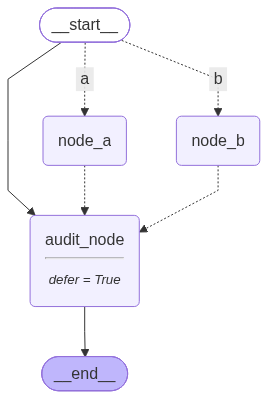

In [6]:
from typing import TypedDict, Literal
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import MessagesState
from langchain.messages import HumanMessage
import os
from rich import print as rprint
from dotenv import load_dotenv
from langchain_openai import ChatOpenAI
from loguru import logger
# 从.env文件中加载环境变量
load_dotenv(override=True, verbose=True,dotenv_path="/Users/skk/Developer/lang-chain-learn/conf/.env")

OPENAI_API_KEY = os.environ["OPENAI_API_KEY"]
OPENAI_API_BASE = os.environ["OPENAI_API_BASE"]  # 与本项目 .env 中的名称一致

model = ChatOpenAI(
    model="gpt-6-sol",  # 当前配置已验证可用；原 gpt-5.5 返回模型权限 403
    api_key=OPENAI_API_KEY,
    base_url=OPENAI_API_BASE,
)

class OverAllState(TypedDict):
    topic: str
    poem: str
    joke: str
    content_type: str

def router(state: OverAllState) -> Literal["node_a", "node_b"]:
    if "诗" in state["content_type"]:
        return "a"
    return "b"


def node_a(state: OverAllState) -> OverAllState:
    poem = model.invoke(
        [
            HumanMessage(f"写一首关于 {state['topic']} 的七言绝句")
        ]
    ).content
    return {
        "poem": poem
    }

def node_b(state: OverAllState) -> OverAllState:
    joke = model.invoke(
        [
            HumanMessage(f"写一个关于 {state['topic']} 的笑话")
        ]
    ).content
    return {
        "joke": joke
    }

def audit_node(state: OverAllState) -> OverAllState:
    logger.info(f"任务节点全部执行完毕，诗 {'已生成' if state.get('poem') else '未生成'}，笑话 {'已生成' if state.get('joke') else '未生成'}")

builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_node("audit_node", audit_node, defer=True)
builder.add_conditional_edges(START,router,{
    "a": "node_a",
    "b": "node_b",
})
builder.add_edge(START, "audit_node")

graph = builder.compile()
res = graph.invoke({"topic": "猫咪",'content_type':"诗"})
rprint(res)
print("====="*10)
res = graph.invoke({"topic": "猫咪",'content_type':"笑话"})
print("====="*10)
rprint(res)
from IPython.display import display

display(graph)

In [7]:
for chunk in graph.stream({"topic": "猫咪",'content_type':"笑话"}, stream_mode="debug"):
    rprint(chunk)

{
    'step': 1,
    'timestamp': '2026-10-15T04:56:58.823028+00:00',
    'type': 'task',
    'payload': {
        'id': '443317e3-1202-ba0f-1bbe-db60b349a588',
        'name': 'node_b',
        'input': {'topic': '猫咪', 'content_type': '笑话'},
        'triggers': ('branch:to:node_b',)
    }
}

{
    'step': 1,
    'timestamp': '2026-10-15T04:57:02.788541+00:00',
    'type': 'task_result',
    'payload': {
        'id': '443317e3-1202-ba0f-1bbe-db60b349a588',
        'name': 'node_b',
        'error': None,
        'result': {'joke': '猫咪为什么喜欢上网？\n\n因为它想多“喵”几声。'},
        'interrupts': []
    }
}

{
    'step': 2,
    'timestamp': '2026-10-15T04:57:02.788827+00:00',
    'type': 'task',
    'payload': {
        'id': 'd57e5d37-f0e1-31fa-c1eb-239ccd5d2d60',
        'name': 'audit_node',
        'input': {
            'topic': '猫咪',
            'joke': '猫咪为什么喜欢上网？\n\n因为它想多“喵”几声。',
            'content_type': '笑话'
        },
        'triggers': ('branch:to:audit_node',)
    }
}

2026-10-14 21:57:02.793 | INFO     | __main__:audit_node:55 - 任务节点全部执行完毕，诗 未生成，笑话 已生成


{
    'step': 2,
    'timestamp': '2026-10-15T04:57:02.794547+00:00',
    'type': 'task_result',
    'payload': {
        'id': 'd57e5d37-f0e1-31fa-c1eb-239ccd5d2d60',
        'name': 'audit_node',
        'error': None,
        'result': {},
        'interrupts': []
    }
}

# 总结

## 1. 三种 `invoke()` 的输入与输出

以下以课程中的普通聊天模型、`create_agent()` 创建的 Agent，以及默认调用方式下的 `StateGraph` 为例。

| 调用 | 常见输入 | 返回值 | 如何读取结果 |
| --- | --- | --- | --- |
| `model.invoke()` | 字符串或消息列表，例如 `"你好"`、`[HumanMessage(content="你好")]` | 一条 `AIMessage`，包含回复内容和相关元数据 | `result.content` |
| `agent.invoke()` | Agent 状态字典，例如 `{"messages": [HumanMessage(content="你好")]}` | 输出状态字典，其中 `messages` 是消息列表，可能包含用户消息、模型回复和工具消息 | 最后一条消息：`result["messages"][-1]`；其内容：`result["messages"][-1].content` |
| `graph.invoke()` | 符合输入 Schema 的状态数据，例如 `{"topic": "猫咪"}` | 按输出 Schema 筛选后的最终状态；本笔记的 `TypedDict` 示例返回字典，例如 `{"topic": "猫咪", "poem": "……", "joke": "……"}` | 按状态字段读取，例如 `result["poem"]`、`result["joke"]` |

未单独配置 `input_schema` 和 `output_schema` 时，图默认使用 `state_schema` 作为输入和输出 Schema。

`model.invoke()` 接收消息列表，`agent.invoke()` 接收包含 `messages` 字段的状态字典，注意这两种输入的外层结构不同。

## 2. Channel：节点之间的通信媒介

**一句话**：Channel 是 LangGraph 运行时里节点之间唯一的通信方式。节点之间不互相调用，也不直接修改 State，只做两件事：**从 channel 读，往 channel 写**。每个 channel 自带两条规则：

- **合并规则**（`update()`）：同一超步里收到的多个写入怎么合并；
- **触发规则**（`is_available()`）：什么时候算"有新值"，可以触发下游节点。

State 字段是 channel，边也是 channel。所以 reducer 和 defer 底层是同一套机制。

### 2.1 两类 channel

4.2.1.6 的 defer 图编译后，`graph.channels` 如下：

```text
topic / poem / joke / content_type   LastValue             ← 数据 channel：State 字段，存值，节点从这里读出 state
__start__                            EphemeralValue        ┐
branch:to:node_a                     EphemeralValue        │ 控制 channel：边，传递"该你执行了"的信号
branch:to:node_b                     EphemeralValue        │
branch:to:audit_node                 LastValueAfterFinish  │ ← defer=True 只改变了这一个
__pregel_tasks                       Topic                 ┘ ← 存放 Send 发出的任务
```

debug 输出里的 `'triggers': ('branch:to:audit_node',)`，就是触发该节点的控制 channel。

### 2.2 常见类型

| 类型 | 合并规则 | 何时可用 | 用在哪里 / 解释了什么 |
|---|---|---|---|
| `LastValue` | 只接受一个值并覆盖；一步收到多个值就抛 `InvalidUpdateError` | 有值时 | 没有 reducer 的字段。解释了 01 中并行写 `cur_id` 的报错 |
| `BinaryOperatorAggregate` | 依次执行 `reducer(旧值, 新值)` | 通常始终可用（初始值为 `typ()`，如 `[]`、`""`） | 有 reducer 的字段。解释了 03 中 `'->start'` 前的空字符串 |
| `EphemeralValue` | 只保留一个超步，下一步没有新写入就清空 | 本步被写入过 | 普通边 `branch:to:X` |
| `LastValueAfterFinish` | 先存下值，但标记为"未完成" | 有值，**并且** `finish()` 已被调用 | `defer=True` 节点的入边 |
| `NamedBarrierValue` | 记录哪些上游已经写入 | 指定的上游**全部**写入后 | `add_edge(["a", "b"], "c")`，即 4.3.1.1 的"与"汇聚 |
| `Topic` | 把多个值累积起来 | 有值时 | `Send` 动态分支（4.2.2、MapReduce） |

### 2.3 一个超步里 channel 如何工作

1. **选节点**：上一步被更新、并且可用的 channel 记录在 `updated_channels` 中。某个节点的 `triggers` 出现在其中，本步就执行它。
2. **读**：节点从它需要的数据 channel 取值，组装成 state 传入。
3. **写**：节点返回的 `{"poem": ...}` 写入数据 channel；同时，出边向 `branch:to:下游节点` 写入一个信号。
4. **合并**：每个 channel 用自己的 `update()` 合并本步收到的所有写入。reducer 就在这一步执行，所以 reducer 是框架在一步结束后统一调用的（03 的结论）。
5. **收尾**：如果 `updated_channels` 中已经没有任何触发 channel，说明常规流程结束。框架对所有 channel 调用 `finish()`，再检查一次是否有 channel 变为可用。

第 4、5 步的源码在 `langgraph/pregel/_algo.py` 的 `apply_writes()` 中。

### 2.4 defer 的本质

`defer=True` 只是把该节点入边的 channel 从 `EphemeralValue` 换成了 `LastValueAfterFinish`：

- 常规流程中，上游写入了 `branch:to:audit_node`，但它还不可用，触发不了节点（第 4 步）；
- 常规流程结束、`finish()` 被调用后，它才变为可用，于是多出一个超步来执行 `audit_node`（第 5 步）。

下方实验对比了 `START → a → audit`、同时 `START → b1 → b2` 的图：

```text
defer=False:  step1: a, b1   step2: audit, b2           → audit 看到 ['a', 'b1']
defer=True:   step1: a, b1   step2: b2    step3: audit  → audit 看到 ['a', 'b1', 'b2']
```

**注意**：defer 只推迟一个**已经发出**的触发信号，不会自己产生信号。`finish()` 要求 channel 中已经有值才会生效，所以 defer 节点必须有入边。本笔记最初没有给 `audit_node` 加入边，它从未执行；补上 `add_edge(START, "audit_node")` 后才正常运行。

In [ ]:
# 实验：defer 对执行时机的影响，并查看编译后的 channel（不调用模型）
from typing import TypedDict, Annotated
from operator import add
from langgraph.graph import StateGraph, START

class DemoState(TypedDict):
    logs: Annotated[list[str], add]

def make_node(name):
    return lambda state: {"logs": [name]}

def audit(state: DemoState):
    return {"logs": [f"audit(看到 {state['logs']})"]}

def build_demo(defer: bool):
    builder = StateGraph(DemoState)
    for name in ("a", "b1", "b2"):
        builder.add_node(name, make_node(name))
    builder.add_node("audit", audit, defer=defer)  # ← 唯一的变量
    builder.add_edge(START, "a")
    builder.add_edge(START, "b1")
    builder.add_edge("b1", "b2")
    builder.add_edge("a", "audit")
    return builder.compile()

for defer in (False, True):
    demo_graph = build_demo(defer)
    print(f"defer={defer}")
    for event in demo_graph.stream({"logs": []}, stream_mode="debug"):
        if event["type"] == "task":
            print(f"  step {event['step']}: {event['payload']['name']}")
    print("  最终 logs:", demo_graph.invoke({"logs": []})["logs"])

print("\ndefer=True 时编译出的 channel：")
for name, channel in demo_graph.channels.items():
    print(f"  {name:20s} {type(channel).__name__}")
print("\n各节点的触发 channel：")
for name, node in demo_graph.nodes.items():
    print(f"  {name:10s} triggers={node.triggers}")

# 1. 问题

### 1. 为什么条件分支绘制的边在返回列表节点时没有绘制出来

router 的返回值在运行时决定真实走向；而 display(graph) / draw_mermaid() 只是把编译期收集到的静态结构元数据画出来。图渲染器读不到 router 的运行时返回值，它只能看到：

* 静态边（add_edge）；
* 条件边的 source；
* 条件边的候选目标集合（这个集合要么来自 path_map，要么来自路由函数的裸 Literal[...] 返回注解）。

router 的信息不足，绘制出的图就会不正确。而我们分支路由为:
```python
def router(state: OverAllState) -> Sequence[Literal["node_a", "node_b", "node_c"]]:
```

在langgraph 解析图时,源代码为如下，可以识别裸 Literal["a","b"]，但是无法识别Sequence[Literal["a","b"]]，会导致end 被推断`None`.最后的 `mermaid`代码也出现错误。
```python
if rtn_type := get_type_hints(func).get("return"):
    if get_origin(rtn_type) is Literal:      # ← 只认“裸 Literal”
        path_map_ = {name: name for name in get_args(rtn_type)}
```

path_map 直接把候选目标集合喂给渲染器，绕开了类型注解推断这一环：
```python
builder.add_conditional_edges(START, router, path_map=["node_a", "node_b", "node_c"])
```

### 这里我还是没懂

**并行路由、`path_map` 与绘图：**

- `router` 返回 `["node_a", "node_c"]`，表示从条件边的起点同时触发两个节点，二者在同一超步并行运行，所以不需要 `node_a → node_c` 的边。
- `path_map` 将路由返回值映射到节点，并提供静态候选目标。同名映射不会改变本例的运行逻辑，本次执行哪些节点仍由 `router` 决定。
- 结构图展示所有可能的连接；它不表示某次运行的轨迹，也不表达哪些分支必须一起选中。
- 当前版本无法从 `Sequence[Literal[...]]` 推断候选目标，省略 `path_map` 会导致本例绘图缺边，但运行时仍能按返回的节点名路由。可显式传入 `path_map=["node_a", "node_b", "node_c"]` 完善绘图。
- `node_c` 返回的 `ci_poem` 需要在 `OverAllState` 中声明，否则节点虽然执行，结果也不会写入状态。